# Diamond Price Prediction

Predicting the price of ~54,000 round-cut diamonds from their weight, cut, color, clarity and dimensions.

**Steps:** EDA → outlier detection (IQR) → ordinal encoding → manual shuffle & split → Linear Regression, K-Fold cross-validation and kNN regression on the original vs. outlier-removed data → effect of feature scaling.

## Dataset
The `diamonds` dataset that ships with seaborn (`sns.load_dataset("diamonds")`), so no download is needed.

**Features:**


* Cut: The quality of the diamond's cut, which affects how well it reflects light; Ideal is the best cut quality.
* Color: The diamond's color grade, where D is completely colorless (best) and J has noticeable yellow tint (worst).
* Clarity: The clarity grade measuring internal flaws (inclusions); IF (Internally Flawless) is best, I1 (Included) is worst.
* Carat: The weight of the diamond; 1 carat = 0.2 grams (ranges from 0.2 to 5.01 carats).
* Depth: The total depth percentage, calculated as z / mean(x, y), representing the height from culet to table divided by average diameter (ranges from 43% to 79%).
* Table: The width of the diamond's top facet (table) relative to its widest point (ranges from 43% to 95%).
* x: The length of the diamond in millimeters (ranges from 0 to 10.74 mm).
* y: The width of the diamond in millimeters (ranges from 0 to 58.9 mm).
* z: The depth/height of the diamond in millimeters (ranges from 0 to 31.8 mm).
* Price: The price of the diamond in US dollars, ranging from \$326 to \$18,823.

In [1]:
# Import required libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

## 1. Exploratory Data Analysis
Missing values, price against each feature, and correlations between numeric features.

In [2]:
diamonds=sns.load_dataset("diamonds")
df=diamonds.copy()
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [4]:
df.isnull().sum()   # no missing values in any column

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

<Axes: xlabel='color', ylabel='price'>

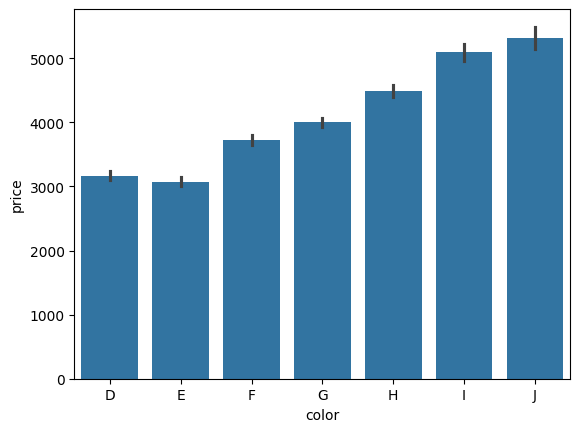

In [5]:
sns.barplot(x="color",y="price",data=df)

<Axes: xlabel='cut', ylabel='price'>

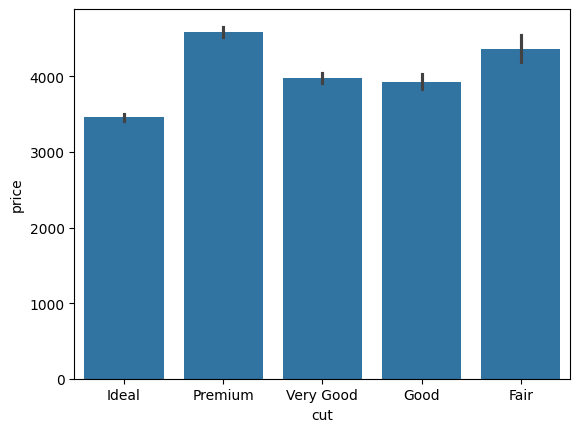

In [6]:
sns.barplot(x="cut",y="price",data=df)

<Axes: xlabel='clarity', ylabel='price'>

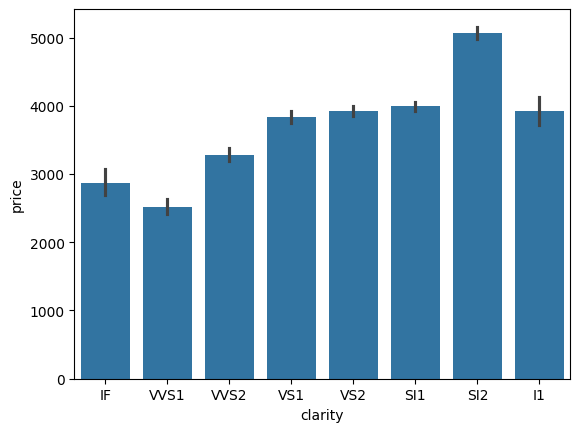

In [7]:
sns.barplot(x="clarity",y="price",data=df)

<Axes: xlabel='carat', ylabel='price'>

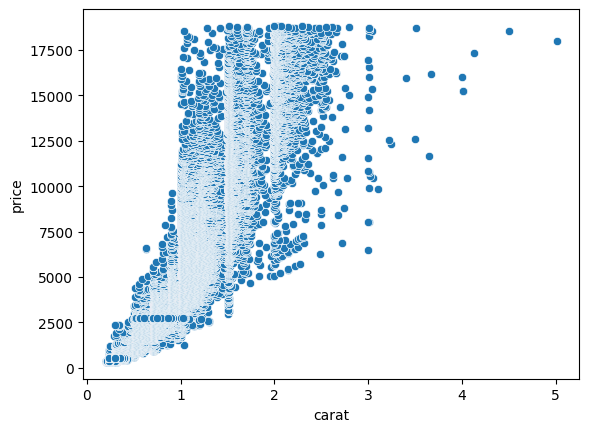

In [8]:
sns.scatterplot(x="carat",y="price",data=df)

<Axes: xlabel='depth', ylabel='price'>

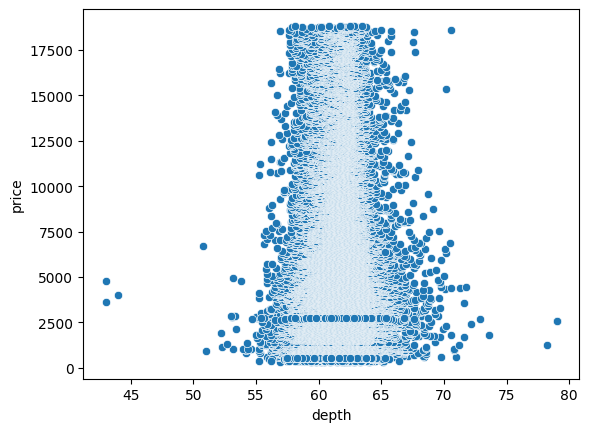

In [9]:
sns.scatterplot(x="depth",y="price",data=df)

<Axes: xlabel='table', ylabel='price'>

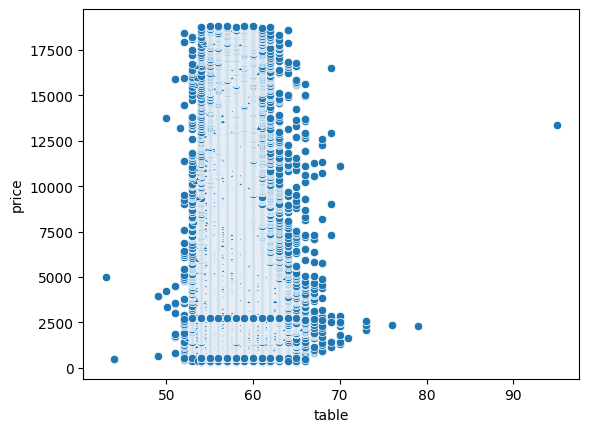

In [10]:
sns.scatterplot(x="table",y="price",data=df)

<Axes: xlabel='x', ylabel='price'>

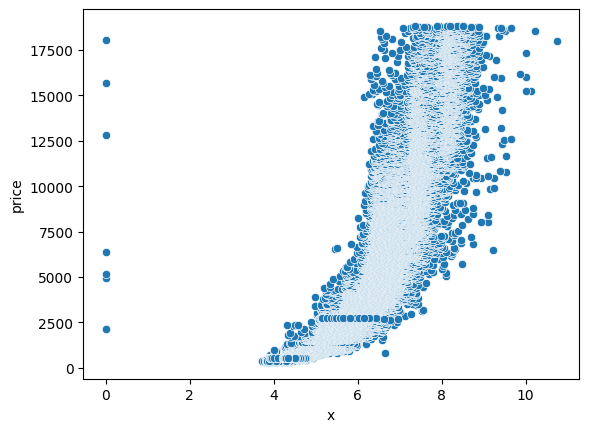

In [11]:
sns.scatterplot(x="x",y="price",data=df)

<Axes: xlabel='y', ylabel='price'>

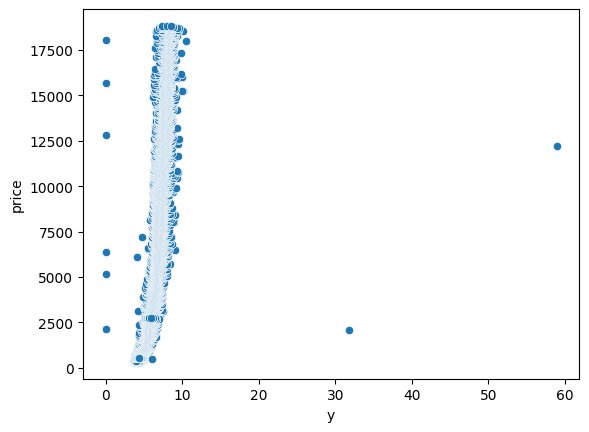

In [12]:
sns.scatterplot(x="y",y="price",data=df)

<Axes: xlabel='z', ylabel='price'>

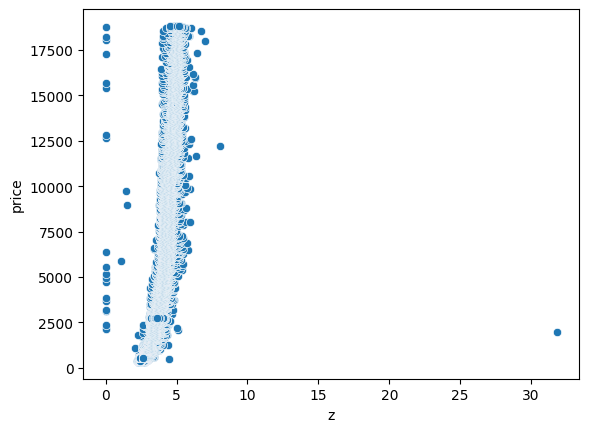

In [13]:
sns.scatterplot(x="z",y="price",data=df)

<Axes: >

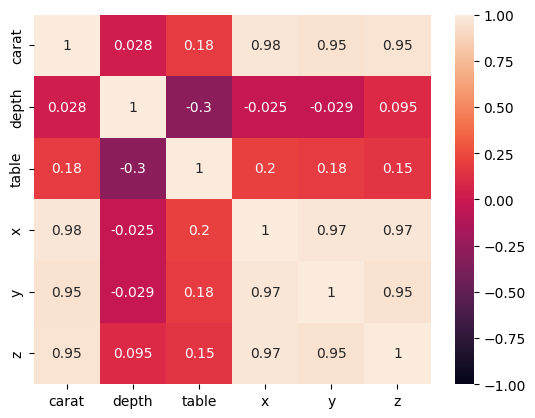

In [14]:
selected_features=df[["carat","depth","table","x","y","z"]]
correlation=selected_features.corr()

sns.heatmap(correlation,vmin=-1,vmax=1,annot=True)

## 2. Outlier Detection (IQR)
For each numeric feature, values below Q1 − 1.5·IQR or above Q3 + 1.5·IQR are marked as outliers.

In [15]:
Q3_carat=df["carat"].quantile(0.75)
Q2_carat=df["carat"].quantile(0.50)
Q1_carat=df["carat"].quantile(0.25)

Q3_depth=df["depth"].quantile(0.75)
Q2_depth=df["depth"].quantile(0.50)
Q1_depth=df["depth"].quantile(0.25)

Q3_table=df["table"].quantile(0.75)
Q2_table=df["table"].quantile(0.50)
Q1_table=df["table"].quantile(0.25)

Q3_x=df["x"].quantile(0.75)
Q2_x=df["x"].quantile(0.50)
Q1_x=df["x"].quantile(0.25)

Q3_y=df["y"].quantile(0.75)
Q2_y=df["y"].quantile(0.50)
Q1_y=df["y"].quantile(0.25)

Q3_z=df["z"].quantile(0.75)
Q2_z=df["z"].quantile(0.50)
Q1_z=df["z"].quantile(0.25)

# IQR=Q3-Q1
IQR_carat=Q3_carat-Q1_carat       
IQR_depth=Q3_depth-Q1_depth
IQR_table=Q3_table-Q1_table
IQR_x=Q3_x-Q1_x
IQR_y=Q3_y-Q1_y
IQR_z=Q3_z-Q1_z

# calculate min and max values for our range ----->  min=Q1-1.5*IQR  ----->  max=Q3+1.5*IQR
# if anyone deviates from these values, they are considered outliers
minCarat=Q1_carat-(1.5*IQR_carat)
maxCarat=Q3_carat+(1.5*IQR_carat)

minDepth=Q1_depth-(1.5*IQR_depth)
maxDepth=Q3_depth+(1.5*IQR_depth)

minTable=Q1_table-(1.5*IQR_table)
maxTable=Q3_table+(1.5*IQR_table)

minX=Q1_x-(1.5*IQR_x)
maxX=Q3_x+(1.5*IQR_x)

minY=Q1_y-(1.5*IQR_y)
maxY=Q3_y+(1.5*IQR_y)

minZ=Q1_z-(1.5*IQR_z)
maxZ=Q3_z+(1.5*IQR_z)

In [16]:
outliers_carat=df[(df["carat"]<minCarat) | (df["carat"]>maxCarat)]
len(outliers_carat["carat"])

1889

In [17]:
outliers_depth=df[(df["depth"]<minDepth) | (df["depth"]>maxDepth)]
len(outliers_depth["depth"])

2545

In [18]:
outliers_table=df[(df["table"]<minTable) | (df["table"]>maxTable)]
len(outliers_table["table"])

605

In [19]:
outliers_x=df[(df["x"]<minX) | (df["x"]>maxX)]
len(outliers_x["x"])

32

In [20]:
outliers_y=df[(df["y"]<minY) | (df["y"]>maxY)]
len(outliers_y["y"])

29

In [21]:
outliers_z=df[(df["z"]<minZ) | (df["z"]>maxZ)]
len(outliers_z["z"])

49

**Why IQR?** The data contains many extreme values and the features are not normally distributed. IQR does not assume a normal distribution and is simple to apply per feature (carat, depth, table, x, y, z).

## 3. Outlier Removal
The original data is kept as a checkpoint; the cleaned version is compared with box plots.

In [22]:
df=df.copy()
cleaned_data=df[(minCarat<=df["carat"]) & (df["carat"]<=maxCarat)&
                (minDepth<=df["depth"]) & (df["depth"]<=maxDepth)&
                (minTable<=df["table"]) & (df["table"]<=maxTable)&
                (minX<=df["x"]) & (df["x"]<=maxX)&
                (minY<=df["y"]) & (df["y"]<=maxY)&
                (minZ<=df["z"]) & (df["z"]<=maxZ)]

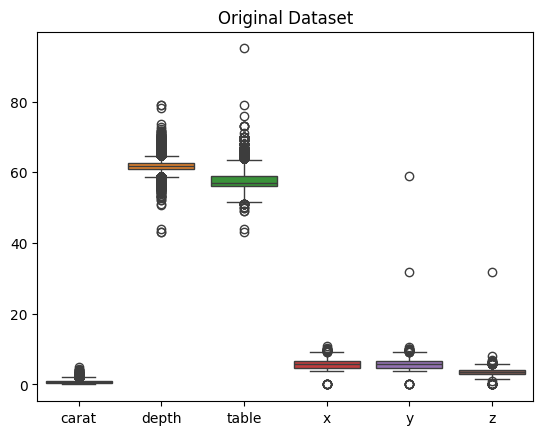

In [23]:
sns.boxplot(data=df[["carat","depth","table","x","y","z"]])
plt.title("Original Dataset")
plt.show()

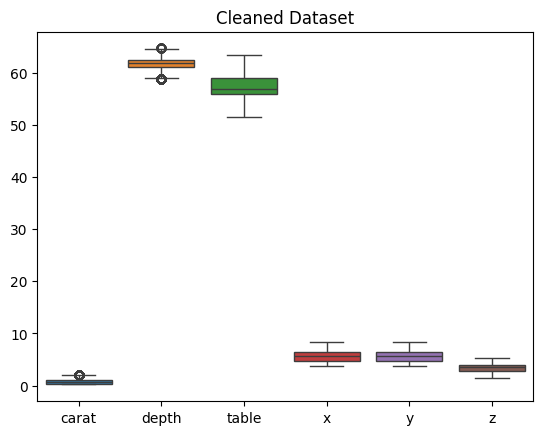

In [24]:
sns.boxplot(data=cleaned_data[["carat","depth","table","x","y","z"]])
plt.title("Cleaned Dataset")
plt.show()

The two plots show that most outliers are gone after cleaning.

## 4. Ordinal Encoding
`cut`, `color` and `clarity` have a natural order, so they are mapped to integers that keep that order.

In [25]:
print(df['cut'].unique())
print(df['color'].unique())
print(df['clarity'].unique())

['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Categories (5, object): ['Ideal', 'Premium', 'Very Good', 'Good', 'Fair']
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Categories (7, object): ['D', 'E', 'F', 'G', 'H', 'I', 'J']
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Categories (8, object): ['IF', 'VVS1', 'VVS2', 'VS1', 'VS2', 'SI1', 'SI2', 'I1']


In [26]:
clarity_encoding = {
    "I1": 0,
    "SI2": 1,
    "SI1": 2,
    "VS2": 3,
    "VS1": 4,
    "VVS2": 5,
    "VVS1": 6,
    "IF": 7,
}

cut_encoding = {
    "Fair": 0,
    "Good": 1,
    "Very Good": 2,
    "Premium": 3,
    "Ideal": 4,
}

color_encoding = {
    "D": 6,
    "E": 5,
    "F": 4,
    "G": 3,
    "H": 2,
    "I": 1,
    "J": 0,
}

df['cut'] = df['cut'].astype(str).str.strip()
df['color'] = df['color'].astype(str).str.strip()
df['clarity'] = df['clarity'].astype(str).str.strip()


df['clarity'] = df['clarity'].map(clarity_encoding)
df['cut'] = df['cut'].map(cut_encoding)
df['color'] = df['color'].map(color_encoding)

cleaned_data['clarity'] = cleaned_data['clarity'].map(clarity_encoding)
cleaned_data['cut'] = cleaned_data['cut'].map(cut_encoding)
cleaned_data['color'] = cleaned_data['color'].map(color_encoding)

df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,4,6,2,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,1,6,2,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,2,6,2,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,3,2,1,61.0,58.0,2757,6.15,6.12,3.74


## 5. Manual Shuffle and Train/Test Split (70/30)
Written by hand (Fisher–Yates shuffle) instead of using `train_test_split` or `shuffle`.

In [27]:
df=df.copy()
n=len(df)
index_list=list(range(n))
for i in range(n-1):
    j=np.random.randint(i,n)
    index_list[i],index_list[j]=index_list[j],index_list[i]

shuffled_df=df.iloc[index_list]
training_len=int(len(shuffled_df)*0.7)

training_set=shuffled_df.iloc[:training_len]
test_set=shuffled_df.iloc[training_len:]

In [28]:
training_set

,carat,cut,color,clarity,depth,table,price,x,y,z
35850,0.33,4,5,5,61.6,55.0,917,4.43,4.47,2.74
26914,2.13,3,3,1,60.7,60.0,16931,8.37,8.27,5.05
50841,0.70,1,5,1,57.8,61.0,2310,5.88,5.82,3.38
28840,0.41,4,6,1,62.7,55.0,683,4.72,4.75,2.97
23538,2.00,3,3,1,61.4,59.0,11544,8.14,8.06,4.97
...,...,...,...,...,...,...,...,...,...,...
3774,0.80,2,4,4,63.7,56.0,3460,5.87,5.90,3.75
12638,1.06,2,1,4,58.5,58.3,5293,6.66,6.79,3.94
19299,1.07,3,5,4,59.7,61.0,8015,6.69,6.64,3.98
52857,0.72,2,5,2,62.1,57.0,2578,5.69,5.75,3.55


In [29]:
test_set

,carat,cut,color,clarity,depth,table,price,x,y,z
24852,1.83,4,5,1,62.8,56.0,13254,7.82,7.76,4.89
22030,0.34,4,2,2,62.6,56.0,628,4.48,4.46,2.80
15943,1.66,4,0,1,60.8,57.0,6377,7.68,7.65,4.66
7399,0.33,3,1,5,62.2,59.0,579,4.41,4.47,2.76
26211,1.59,3,4,3,60.2,60.0,15602,7.62,7.59,4.58
...,...,...,...,...,...,...,...,...,...,...
22350,0.31,2,1,4,63.5,57.0,628,4.28,4.26,2.71
31080,0.30,2,6,5,62.9,56.0,752,4.27,4.29,2.69
44257,0.51,4,2,5,61.0,57.0,1574,5.22,5.18,3.17
525,1.17,3,0,0,60.2,61.0,2825,6.90,6.83,4.13


## 6. Regression
Target: `price`. Predictors: all other features.

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

### 6.1 Linear Regression — original vs. outlier-removed data

In [31]:
datasets={
    "original":df.copy(),
    "no outliers":cleaned_data.copy()
}
results={}
for name,data in datasets.items():
    X=data.drop("price",axis=1)
    Y=data["price"]

    X_train, X_test, Y_train, Y_test=train_test_split(X,Y,test_size=0.3,random_state=1)

    model=LinearRegression()
    model.fit(X_train,Y_train)

    Y_predict=model.predict(X_test)

    summation=0
    for i in range(len(Y_test)):
        summation += (Y_test.iloc[i] - Y_predict[i]) ** 2

    mse=summation/len(Y_test)

    results[name]=mse

for name,mse in results.items():
    print(f"{name:30} → Test MSE: {mse:,.2f}")

  

original                       → Test MSE: 1,399,641.55
no outliers                    → Test MSE: 1,075,472.78


The MSE of the clean data is lower than the original data. This means the model makes smaller errors after we remove the outliers. The model learns better and gives more stable results. Outliers make the model confused, so without them the model can generalize better.

### 6.2 K-Fold Cross-Validation
Mean and standard deviation of R² and RMSE show generalization and stability.

In [32]:
resultsCV={}
for name,data in datasets.items():
    X=data.drop("price",axis=1)
    Y=data["price"]

    X_train, X_test, Y_train, Y_test=train_test_split(X,Y,test_size=0.3,random_state=1)

    model=LinearRegression()
    model.fit(X_train,Y_train)

    calculate_r2=cross_val_score(model,X_train,Y_train,scoring='r2')

    calculate_rmse=cross_val_score(model,X_train,Y_train,scoring='neg_root_mean_squared_error')

    results[name]={
                   "R2 Mean":calculate_r2.mean(),
                   "R2 Std":calculate_r2.std(),
                   "RMSE Mean":-calculate_rmse.mean(),
                   "RMSE Std":calculate_rmse.std()
                   }

for name, metrics in results.items():
    print(f"\n---> {name} <---")
    print(f"Mean R² (generalization): {metrics['R2 Mean']:.4f}")
    print(f"R² std (stability): {metrics['R2 Std']:.4f}")
    print(f"Mean RMSE: {metrics['RMSE Mean']:.2f}")
    print(f"RMSE std: {metrics['RMSE Std']:.2f}")


---> original <---
Mean R² (generalization): 0.9060
R² std (stability): 0.0033
Mean RMSE: 1231.95
RMSE std: 25.19

---> no outliers <---
Mean R² (generalization): 0.9059
R² std (stability): 0.0011
Mean RMSE: 1057.85
RMSE std: 11.88


The Generalization is better because the model now makes a smaller average error (RMSE is lower). This means the prediction is more accurate on new data. The $\text{R}^2$ average stayed almost the same, so we didn't lose much power.

The Stability is also much higher. All our standard deviation values (for both $\text{R}^2$ and RMSE) went down a lot. This shows that the model is very consistent and reliable; it performs the same way on different parts of the data.

### 6.3 kNN Regression (k = 1–10)
MSE vs. k on both dataset versions, then the best version is repeated with standardized features.

---> original dataset <---
k= 1 → MSE=1106279.51, R²=0.9279
k= 2 → MSE=906442.23, R²=0.9409
k= 3 → MSE=816786.18, R²=0.9468
k= 4 → MSE=770721.42, R²=0.9498
k= 5 → MSE=743469.37, R²=0.9515
k= 6 → MSE=730333.49, R²=0.9524
k= 7 → MSE=723769.28, R²=0.9528
k= 8 → MSE=720691.37, R²=0.9530
k= 9 → MSE=723917.22, R²=0.9528
k=10 → MSE=722360.63, R²=0.9529


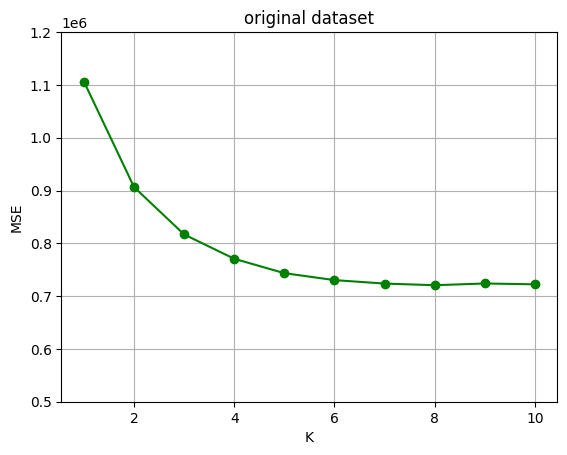

---> no outliers dataset <---
k= 1 → MSE=763905.83, R²=0.9335
k= 2 → MSE=624211.59, R²=0.9456
k= 3 → MSE=570341.45, R²=0.9503
k= 4 → MSE=560172.04, R²=0.9512
k= 5 → MSE=545814.14, R²=0.9525
k= 6 → MSE=535337.07, R²=0.9534
k= 7 → MSE=532751.47, R²=0.9536
k= 8 → MSE=525727.86, R²=0.9542
k= 9 → MSE=524059.47, R²=0.9544
k=10 → MSE=527925.06, R²=0.9540


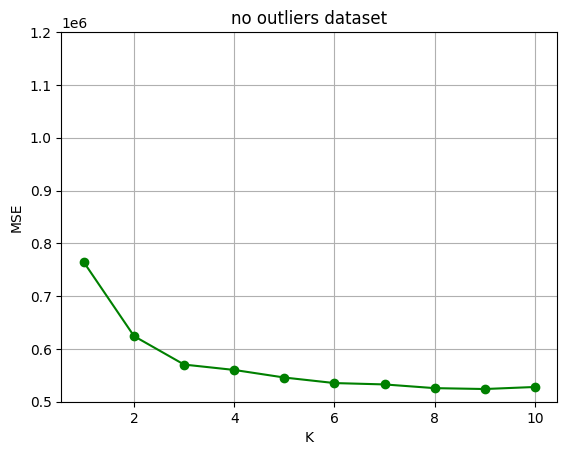

k= 1 → MSE=514671.95, R²=0.9552
k= 2 → MSE=409146.70, R²=0.9644
k= 3 → MSE=382671.49, R²=0.9667
k= 4 → MSE=364690.18, R²=0.9682
k= 5 → MSE=358728.84, R²=0.9688
k= 6 → MSE=350937.74, R²=0.9694
k= 7 → MSE=346186.83, R²=0.9698
k= 8 → MSE=346430.64, R²=0.9698
k= 9 → MSE=347578.49, R²=0.9697
k=10 → MSE=349062.69, R²=0.9696


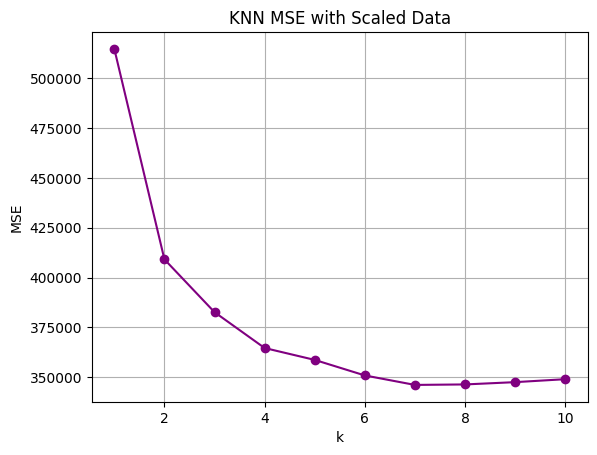

In [33]:
def evaluate_knn(X_train, X_test, Y_train, Y_test, k):
        knn = KNeighborsRegressor(n_neighbors=k)
        knn.fit(X_train, Y_train)
        Y_pred = knn.predict(X_test)

        mse = mean_squared_error(Y_test, Y_pred)
        r2 = r2_score(Y_test, Y_pred)

        return mse, r2   

resultsKNN={}
for name,data in datasets.items():
    X=data.drop("price",axis=1)
    Y=data["price"]

    X_train, X_test, Y_train, Y_test=train_test_split(X,Y,test_size=0.3,random_state=1)

 

    mse_results = []
    r2_results = []
    print(f"---> {name} dataset <---")
    for k in range(1, 11):
        mse, r2 = evaluate_knn(X_train, X_test, Y_train, Y_test, k)
        mse_results.append(mse)
        r2_results.append(r2)
        print(f"k={k:2d} → MSE={mse:.2f}, R²={r2:.4f}")

    
    plt.plot(range(1,11), mse_results, marker='o', color='green')
    plt.title(f"{name} dataset")
    plt.xlabel("K")
    plt.ylabel("MSE")
    plt.grid(True)
    plt.ylim(500000, 1200000)
    plt.show()

    best_k = 1 + mse_results.index(min(mse_results))
    best_mse = min(mse_results)
    best_r2 = r2_results[mse_results.index(best_mse)]

    resultsKNN[name]={
        "best_k": best_k,
        "best_mse": best_mse,
        "best_r2": best_r2
    }


best_dataset_name = min(resultsKNN, key=lambda x: resultsKNN[x]["best_mse"])

best_data = datasets[best_dataset_name]
X = best_data.drop("price", axis=1)
Y = best_data["price"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train_s, X_test_s, Y_train_s, Y_test_s = train_test_split(X_scaled, Y, test_size=0.3, random_state=1)

mse_scaled = []
r2_scaled = []

for k in range(1, 11):
    mse, r2 = evaluate_knn(X_train_s, X_test_s, Y_train_s, Y_test_s, k)
    mse_scaled.append(mse)
    r2_scaled.append(r2)
    print(f"k={k:2d} → MSE={mse:.2f}, R²={r2:.4f}")



plt.plot(range(1,11), mse_scaled, marker='o', color='purple')
plt.title("KNN MSE with Scaled Data")
plt.xlabel("k")
plt.ylabel("MSE")
plt.grid(True)
plt.show()  
    

        
        

When I check the MSE values for KNN, the dataset without outliers gives better results. The MSE is smaller and the curve looks more stable. I think KNN works better here because KNN is very sensitive to outliers. One bad point can change the neighbor distance a lot. When we remove outliers, the neighbors are more normal and the model makes better predictions. So the clean dataset gives the best result.

### 6.4 Comparing the Models

**Compare and contrast**

When I compare the results of kNN and Linear Regression, I see they act different on the datasets. On the original data, both models have high error, but Linear Regression is affected more. kNN is also not stable because the outliers change the distances. After removing outliers, both models get better, but kNN improves more. kNN has lower MSE and the curve looks more smooth. Linear Regression also gets better, but it is still not as good as kNN. So in my results, kNN works better in both datasets, especially in the clean version.

**Strengths and limitations**

*Linear Regression:*
For me, Linear Regression is simple and fast. It trains very quick and the idea is easy: it tries to draw a line. When the data is clean, it works kind of okay and the MSE is smaller. But it has some limits. It cannot learn complex shapes, and when the data has outliers, the model gets confused and the error becomes very big. So Linear Regression is good for simple and clean data, but not good for noisy data.

*kNN:*
kNN feels more flexible. It does not try to draw a line, it looks at neighbors, so it can follow more complex patterns. In my results, kNN gave better MSE, especially after I removed the outliers. But kNN also has some problems. It is slow when the data is big, because it checks all points for every prediction. And kNN needs scaling, because it uses distance. If one feature has very big numbers, the distance becomes strange and the prediction gets worse. Outliers also change the distance and make the model confused. But when the data is clean and scaled, kNN becomes more stable and gives stronger results.

*Overall:*
Based on my results, Linear Regression is good for speed and simple patterns, but kNN is better for accuracy when the data is clean. Both models work better after removing outliers.

## Summary

| Model | Data | Test MSE | R² |
|---|---|---|---|
| Linear Regression | original | 1.40 M | — |
| Linear Regression | outliers removed | 1.08 M | — |
| Linear Regression, 5-fold CV | outliers removed | RMSE 1058 ± 12 | 0.906 ± 0.001 |
| kNN (k = 9) | outliers removed | 0.52 M | 0.954 |
| **kNN (k = 7), standardized** | outliers removed | **0.35 M** | **0.970** |

- Removing outliers lowers the error and makes the model more stable (smaller standard deviation across folds).
- kNN beats Linear Regression, and scaling the features improves kNN further because it is distance-based.